# 03 - Categories and discounts

Main analysis: which source categories generate sales and reach households, and how frequently are the different discount types used? The same paid-line eligibility as notebook 02 applies. This notebook requires transaction_data.csv and product.csv only.

These are aggregate descriptions, not household-specific coupon recommendations or causal promotion effects. The separate placement analysis is in [additional notebooks](../additional/notebooks/01_promotional_placements.ipynb).

**Step 1: Import the required libraries.**

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.figure import Figure

plt.ioff()
from matplotlib.ticker import (
    PercentFormatter,
    StrMethodFormatter,
    FuncFormatter,
    MaxNLocator,
)
from IPython.display import display, Markdown


**Step 2: Prepare ROOT, imports, imports.**

In [2]:
ROOT = next(
    (
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "src/retail_customer_360/metrics.py").is_file()
    ),
    None,
)
if ROOT is None:
    raise RuntimeError("Open the notebook inside the project.")
sys.path.insert(0, str(ROOT / "src"))
from retail_customer_360.metrics import load_transactions, build_metrics, summary
from retail_customer_360.promotions import add_eda_sources

pd.set_option("display.max_columns", 25)


**Step 3: Prepare FIGURES.**

In [3]:
plt.style.use("seaborn-v0_8-whitegrid")
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, TEAL = "#245C83", "#D77931", "#208778"


**Step 4: Define the run_sql helper.**

In [4]:
def run_sql(query):
    display(Markdown("```sql\n" + query.strip() + "\n```"))
    frame = con.execute(query).fetchdf()
    display(frame)
    return frame


**Step 5: Define the finish_figure helper.**

In [5]:
from IPython.display import Image as NotebookImage


def finish_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=160, bbox_inches="tight", facecolor="white")
    display(NotebookImage(filename=str(FIGURES / name)))
    plt.close(fig)


**Step 6: Load data and inspect the input.**

In [6]:
con = load_transactions(ROOT)
first_day, last_day = con.execute("""SELECT min(day),max(day)
FROM raw_transactions""").fetchone()
WINDOW_START_DAY = first_day
AS_OF_DAY = last_day
build_metrics(con, WINDOW_START_DAY, AS_OF_DAY, ROOT)
add_eda_sources(con, ROOT)
base_summary = summary(con, ROOT)
assert (
    con.execute("""SELECT count(*),sum(sales_value)
FROM eda_lines""").fetchone()
    == con.execute("""SELECT count(*),sum(sales_value)
FROM eligible_lines""").fetchone()
)


**Step 7: Check the calculation.**

In [7]:
assert con.execute("""SELECT count(*)
FROM discount_baskets""").fetchone()[0] == base_summary["purchase_baskets"]
window_label = f"Source days {WINDOW_START_DAY} to {AS_OF_DAY}; eligible paid lines"
print(window_label)
print("Category/discount counts and exact sales reconcile with notebook 02.")


Source days 1 to 711; eligible paid lines
Category/discount counts and exact sales reconcile with notebook 02.


## 1. Category joins and sales mix

Categories use `COMMODITY_DESC`, not `DEPARTMENT`. Product identifiers must be unique before joining. Blank categories and `NO COMMODITY DESCRIPTION` become an explicit unknown group; unmatched products remain separate. The chart shows the top 15 categories by eligible retailer sales; the table includes every category.

Household reach uses all households observed by the cutoff. Households can buy from multiple categories, so reach percentages overlap and must not be summed.

**Category interpretation:** labels such as `COUPON/MISC ITEMS` are mixed source classifications. Keep them visible; do not reinterpret them as a specific grocery product group or drop them without investigation.

**Step 8: Calculate and inspect query results.**

In [8]:
display(
    Markdown("```sql\n" + (ROOT / "sql/sales_promotions_eda.sql").read_text() + "\n```")
)
category_quality = run_sql("""SELECT category,count(*) AS eligible_lines,
       sum(sales_value) AS sales
FROM eda_lines
WHERE category IN ('[Unknown category]','[Unmatched product]')
GROUP BY category""")


```sql
-- Same paid-line eligibility and inclusive window as notebook 02.
CREATE TEMP TABLE eda_lines AS
SELECT t.household_key,t.basket_id,t.day,t.product_id,t.store_id,t.week_no,
    t.quantity,t.sales_value,
    t.retail_disc_raw::DECIMAL(18,2) AS retail_disc,
    t.coupon_disc_raw::DECIMAL(18,2) AS coupon_disc,
    t.coupon_match_disc_raw::DECIMAL(18,2) AS coupon_match_disc,
    coalesce(p.department,'[Unmatched product]') AS department,
    coalesce(p.category,'[Unmatched product]') AS category
FROM transaction_context t CROSS JOIN metrics_parameters m
LEFT JOIN product_metadata p USING(product_id)
WHERE t.day BETWEEN m.window_start_day AND m.as_of_day
    AND t.quantity>0 AND t.sales_value>0;

CREATE TEMP TABLE discount_baskets AS
SELECT household_key,basket_id,day,min(week_no) AS week_no,
    bool_or(retail_disc<0) AS has_loyalty_reduction,
    bool_or(coupon_disc<0) AS has_manufacturer_coupon,
    bool_or(coupon_match_disc<0) AS has_coupon_match,
    bool_or(retail_disc>0 OR coupon_disc>0 OR coupon_match_disc>0)
        AS has_positive_adjustment,
    sum(sales_value) AS eligible_sales_value,
    sum(CASE WHEN retail_disc<0 THEN -retail_disc ELSE 0 END) AS loyalty_reduction,
    sum(CASE WHEN coupon_disc<0 THEN -coupon_disc ELSE 0 END) AS manufacturer_reduction,
    sum(CASE WHEN coupon_match_disc<0 THEN -coupon_match_disc ELSE 0 END)
        AS match_reduction
FROM eda_lines GROUP BY household_key,basket_id,day;

```

```sql
SELECT category,count(*) AS eligible_lines,
       sum(sales_value) AS sales
FROM eda_lines
WHERE category IN ('[Unknown category]','[Unmatched product]')
GROUP BY category
```

,category,eligible_lines,sales
0,[Unknown category],2288,10678.69


**Step 9: Calculate and inspect query results.**

In [9]:
category_metrics = run_sql("""SELECT category,sum(sales_value) AS sales,
       count(DISTINCT household_key) AS purchasing_households,
       100.0*count(DISTINCT household_key)/
  (SELECT count(*)
   FROM customer_metrics) AS household_reach_pct,
       count(DISTINCT basket_id) AS baskets_containing_category,
       100.0*sum(sales_value)/
  (SELECT sum(sales_value)
   FROM eda_lines) AS sales_share_pct
FROM eda_lines
GROUP BY category
ORDER BY sales DESC,category""")
top = category_metrics.head(15).iloc[::-1]
fig = Figure(figsize=(14, 7))
axes = fig.subplots(1, 2, sharey=True)
axes[0].barh(top.category, top.sales, color=BLUE)
axes[0].set_xlabel("Eligible retailer sales (USD)")


```sql
SELECT category,sum(sales_value) AS sales,
       count(DISTINCT household_key) AS purchasing_households,
       100.0*count(DISTINCT household_key)/
  (SELECT count(*)
   FROM customer_metrics) AS household_reach_pct,
       count(DISTINCT basket_id) AS baskets_containing_category,
       100.0*sum(sales_value)/
  (SELECT sum(sales_value)
   FROM eda_lines) AS sales_share_pct
FROM eda_lines
GROUP BY category
ORDER BY sales DESC,category
```

,category,sales,purchasing_households,household_reach_pct,baskets_containing_category,sales_share_pct
0,COUPON/MISC ITEMS,639878.46,1973,78.92,27584,7.941457
1,SOFT DRINKS,327645.21,2405,96.20,71545,4.066367
2,BEEF,312103.22,2238,89.52,36695,3.873477
3,FLUID MILK PRODUCTS,205356.05,2421,96.84,69198,2.548650
4,CHEESE,189528.18,2350,94.00,46856,2.352212
...,...,...,...,...,...,...
302,FROZEN PACKAGE MEAT,12.99,1,0.04,1,0.000161
303,NDAIRY/TEAS/JUICE/SOD,11.78,2,0.08,2,0.000146
304,TOYS,9.84,4,0.16,5,0.000122
305,MISCELLANEOUS CROUTONS,6.39,1,0.04,1,0.000079


Text(0.5, 0, 'Eligible retailer sales (USD)')

**Step 10: Finish and display the chart.**

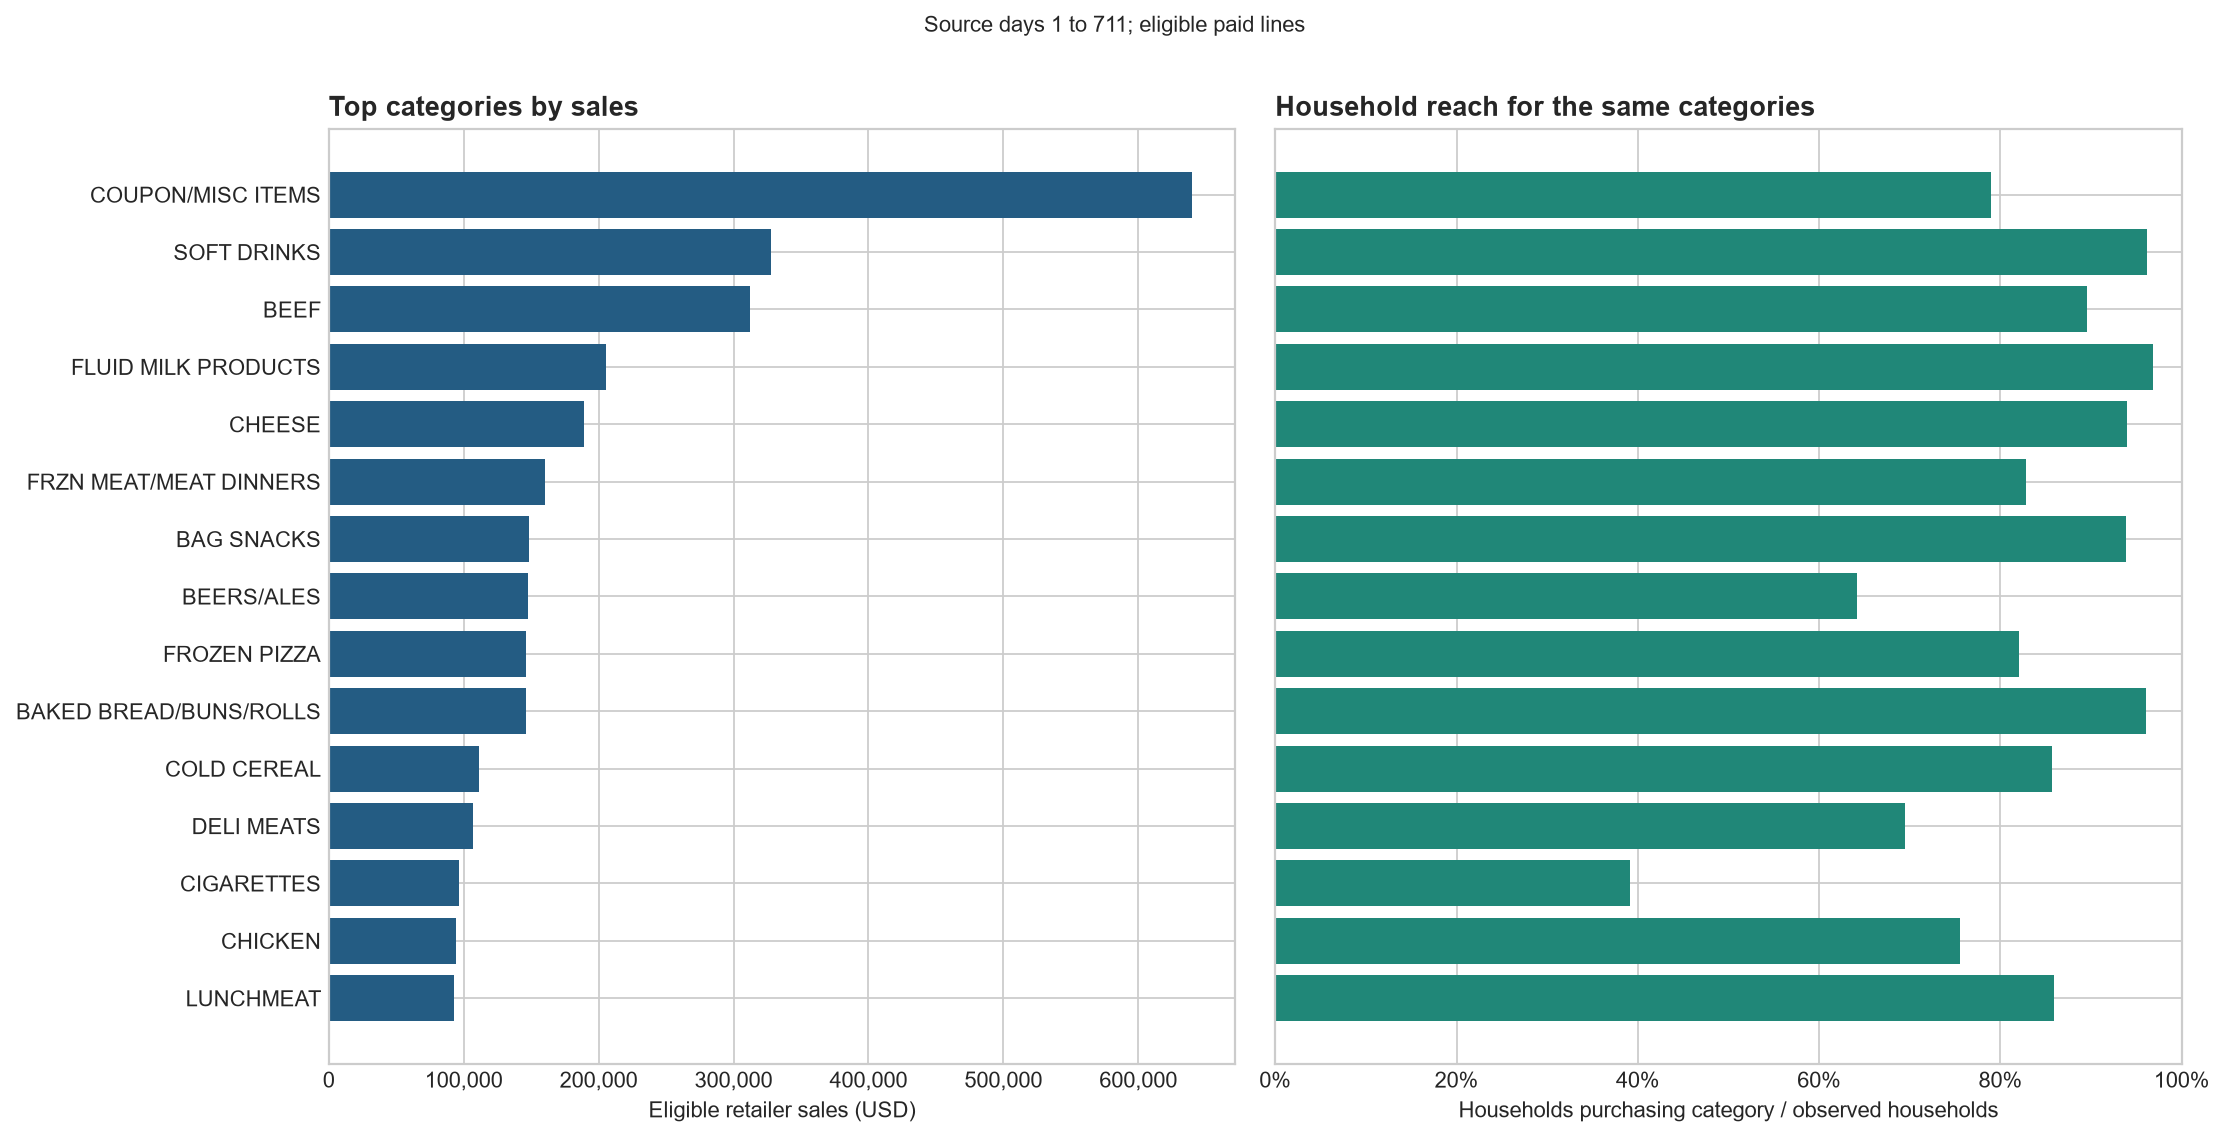

In [10]:
axes[0].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].barh(top.category, top.household_reach_pct, color=TEAL)
axes[1].set_xlabel("Households purchasing category / observed households")
axes[1].xaxis.set_major_formatter(PercentFormatter(100))
axes[1].set_xlim(0, 100)
axes[0].set_title("Top categories by sales", loc="left", fontweight="bold")
axes[1].set_title(
    "Household reach for the same categories", loc="left", fontweight="bold"
)
fig.suptitle(window_label, fontsize=10, y=1.01)
finish_figure(fig, "03_category_sales_and_reach.png")


## 2. Discount frequency: overlapping basket flags

A negative source adjustment denotes a reduction; positive adjustments are reported separately, not converted to discounts with `ABS`. A paid basket qualifies if any eligible line has that reduction type. The three flags overlap, so their percentages may sum above 100%. This view does not cover discounts on excluded free-only or non-positive-quantity lines.

Use original source weeks. Edge weeks with fewer observed days can have unstable shares; the denominator is paid baskets in that week. The accompanying coverage table shows the number of observed source days.

**Step 11: Calculate and inspect query results.**

In [11]:
weekly_discounts = run_sql(
    "SELECT week_no,count(*) AS paid_baskets,\n    "
    "count(DISTINCT day) AS observed_paid_days,\n    "
    "100.0*count(*) FILTER (WHERE "
    "has_loyalty_reduction)/count(*) AS loyalty_pct,\n    "
    "100.0*count(*) FILTER (WHERE "
    "has_manufacturer_coupon)/count(*) AS manufacturer_pct,\n    "
    "100.0*count(*) FILTER (WHERE has_coupon_match)/count(*) AS "
    "match_pct\nFROM discount_baskets GROUP BY week_no ORDER BY "
    "week_no"
)
fig = Figure(figsize=(12, 4.8))
ax = fig.subplots()


```sql
SELECT week_no,count(*) AS paid_baskets,
    count(DISTINCT day) AS observed_paid_days,
    100.0*count(*) FILTER (WHERE has_loyalty_reduction)/count(*) AS loyalty_pct,
    100.0*count(*) FILTER (WHERE has_manufacturer_coupon)/count(*) AS manufacturer_pct,
    100.0*count(*) FILTER (WHERE has_coupon_match)/count(*) AS match_pct
FROM discount_baskets GROUP BY week_no ORDER BY week_no
```

,week_no,paid_baskets,observed_paid_days,loyalty_pct,manufacturer_pct,match_pct
0,1,139,5,92.805755,3.597122,2.877698
1,2,321,7,84.735202,3.115265,1.869159
2,3,480,7,86.250000,5.416667,3.333333
3,4,543,7,85.635359,3.867403,1.657459
4,5,753,7,88.711819,3.585657,2.788845
...,...,...,...,...,...,...
97,98,3027,7,86.521308,6.045590,3.336637
98,99,2841,7,83.808518,4.927842,3.484688
99,100,2784,7,81.824713,4.777299,3.304598
100,101,2675,7,83.738318,5.308411,3.177570


**Step 12: Build the chart.**

In [12]:
for column, label, color in [
    ("loyalty_pct", "Retailer loyalty", BLUE),
    ("manufacturer_pct", "Manufacturer coupon", ORANGE),
    ("match_pct", "Retailer coupon match", TEAL),
]:
    ax.plot(
        weekly_discounts.week_no,
        weekly_discounts[column],
        label=label,
        color=color,
        linewidth=1.8,
    )


**Step 13: Finish and display the chart.**

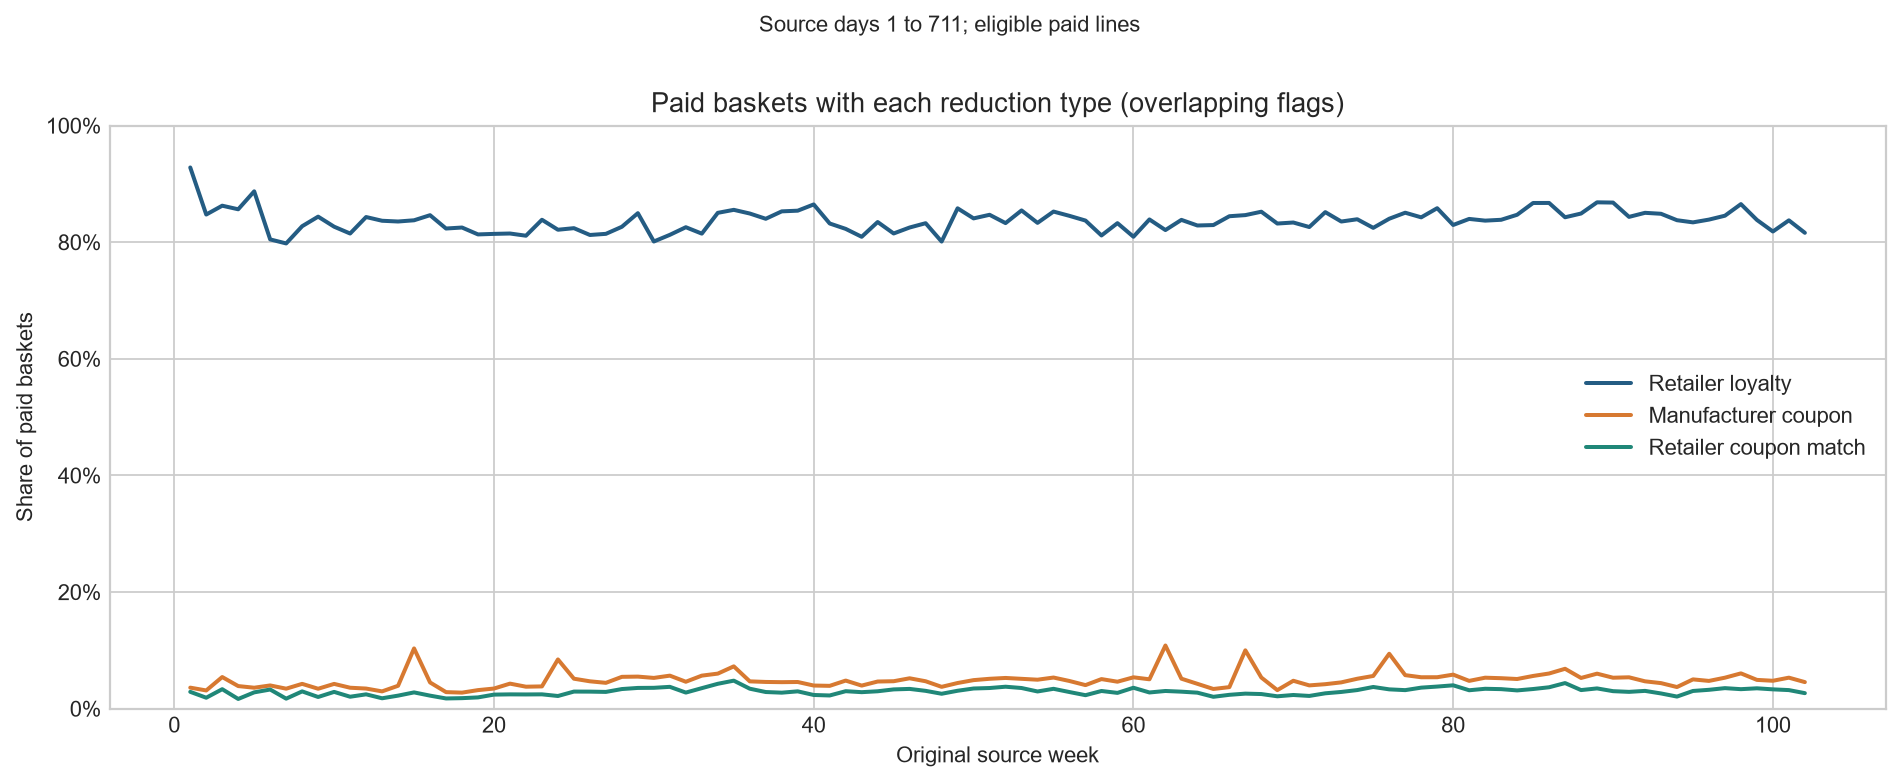

,week_no,observed_paid_days,paid_baskets
0,1,5,139
101,102,6,2375


In [13]:
ax.set(
    xlabel="Original source week",
    ylabel="Share of paid baskets",
    ylim=(0, 100),
    title="Paid baskets with each reduction type (overlapping flags)",
)
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.legend(frameon=False)
fig.suptitle(window_label, fontsize=10, y=1.01)
finish_figure(fig, "03_weekly_discount_usage.png")
display(
    weekly_discounts.loc[
        weekly_discounts.observed_paid_days < 7,
        ["week_no", "observed_paid_days", "paid_baskets"],
    ]
)


## 3. Discount magnitudes and sign exceptions

Sum only negative adjustments, changing their sign for readable reduction magnitudes. Manufacturer coupon funding and retailer-funded adjustments are different concepts; these bars must not be described as a single retailer marketing cost or as incremental sales. No discount percentage of a reconstructed list price is calculated.

The comparison is restricted to eligible paid lines. Positive adjustments on all source lines were reported in the earlier audit; this table reports their eligible subset.

**Step 14: Calculate and inspect query results.**

In [14]:
discount_totals = run_sql(
    "SELECT 'Retailer loyalty' AS type,\n    "
    "sum(loyalty_reduction) AS reduction_usd,\n    "
    "100.0*count(*) FILTER (WHERE "
    "has_loyalty_reduction)/count(*) AS paid_basket_pct\nFROM "
    "discount_baskets UNION ALL\nSELECT 'Manufacturer coupon',"
    "sum(manufacturer_reduction),100.0*count(*) FILTER (WHERE "
    "has_manufacturer_coupon)/count(*) FROM discount_baskets "
    "UNION ALL\nSELECT 'Retailer coupon match',"
    "sum(match_reduction),100.0*count(*) FILTER (WHERE "
    "has_coupon_match)/count(*) FROM discount_baskets"
)


```sql
SELECT 'Retailer loyalty' AS type,
    sum(loyalty_reduction) AS reduction_usd,
    100.0*count(*) FILTER (WHERE has_loyalty_reduction)/count(*) AS paid_basket_pct
FROM discount_baskets UNION ALL
SELECT 'Manufacturer coupon',sum(manufacturer_reduction),100.0*count(*) FILTER (WHERE has_manufacturer_coupon)/count(*) FROM discount_baskets UNION ALL
SELECT 'Retailer coupon match',sum(match_reduction),100.0*count(*) FILTER (WHERE has_coupon_match)/count(*) FROM discount_baskets
```

,type,reduction_usd,paid_basket_pct
0,Retailer loyalty,1383618.63,83.604136
1,Manufacturer coupon,32234.83,5.013446
2,Retailer coupon match,7570.36,2.960742


**Step 15: Calculate and inspect query results.**

In [15]:
positive_adjustments = run_sql("""SELECT count(*) AS positive_adjustment_lines,
       sum(CASE WHEN retail_disc>0 THEN retail_disc ELSE 0
           END) AS positive_loyalty_amount,
       sum(CASE WHEN coupon_disc>0 THEN coupon_disc ELSE 0
           END) AS positive_manufacturer_amount,
       sum(CASE
               WHEN coupon_match_disc>0 THEN coupon_match_disc ELSE 0
           END) AS positive_match_amount
FROM eda_lines
WHERE retail_disc>0
  OR coupon_disc>0
  OR coupon_match_disc>0""")
fig = Figure(figsize=(12, 4.5))
axes = fig.subplots(1, 2)
axes[0].barh(
    discount_totals.type, discount_totals.reduction_usd, color=[BLUE, ORANGE, TEAL]
)


```sql
SELECT count(*) AS positive_adjustment_lines,
       sum(CASE WHEN retail_disc>0 THEN retail_disc ELSE 0
           END) AS positive_loyalty_amount,
       sum(CASE WHEN coupon_disc>0 THEN coupon_disc ELSE 0
           END) AS positive_manufacturer_amount,
       sum(CASE
               WHEN coupon_match_disc>0 THEN coupon_match_disc ELSE 0
           END) AS positive_match_amount
FROM eda_lines
WHERE retail_disc>0
  OR coupon_disc>0
  OR coupon_match_disc>0
```

,positive_adjustment_lines,positive_loyalty_amount,positive_manufacturer_amount,positive_match_amount
0,2,4.25,0.0,0.0


<BarContainer object of 3 artists>

**Step 16: Build the chart.**

In [16]:
axes[0].set(
    xlabel="Recorded reduction magnitude (USD)",
    title="Amounts by funding / adjustment type",
)
axes[0].xaxis.set_major_locator(MaxNLocator(4))
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1_000_000:.1f}m"))
axes[0].set_xlim(0, float(discount_totals.reduction_usd.max()) * 1.3)
axes[0].bar_label(
    axes[0].containers[0],
    labels=[f"${v:,.0f}" for v in discount_totals.reduction_usd],
    padding=4,
    fontsize=9,
)
axes[1].barh(
    discount_totals.type, discount_totals.paid_basket_pct, color=[BLUE, ORANGE, TEAL]
)


<BarContainer object of 3 artists>

**Step 17: Finish and display the chart.**

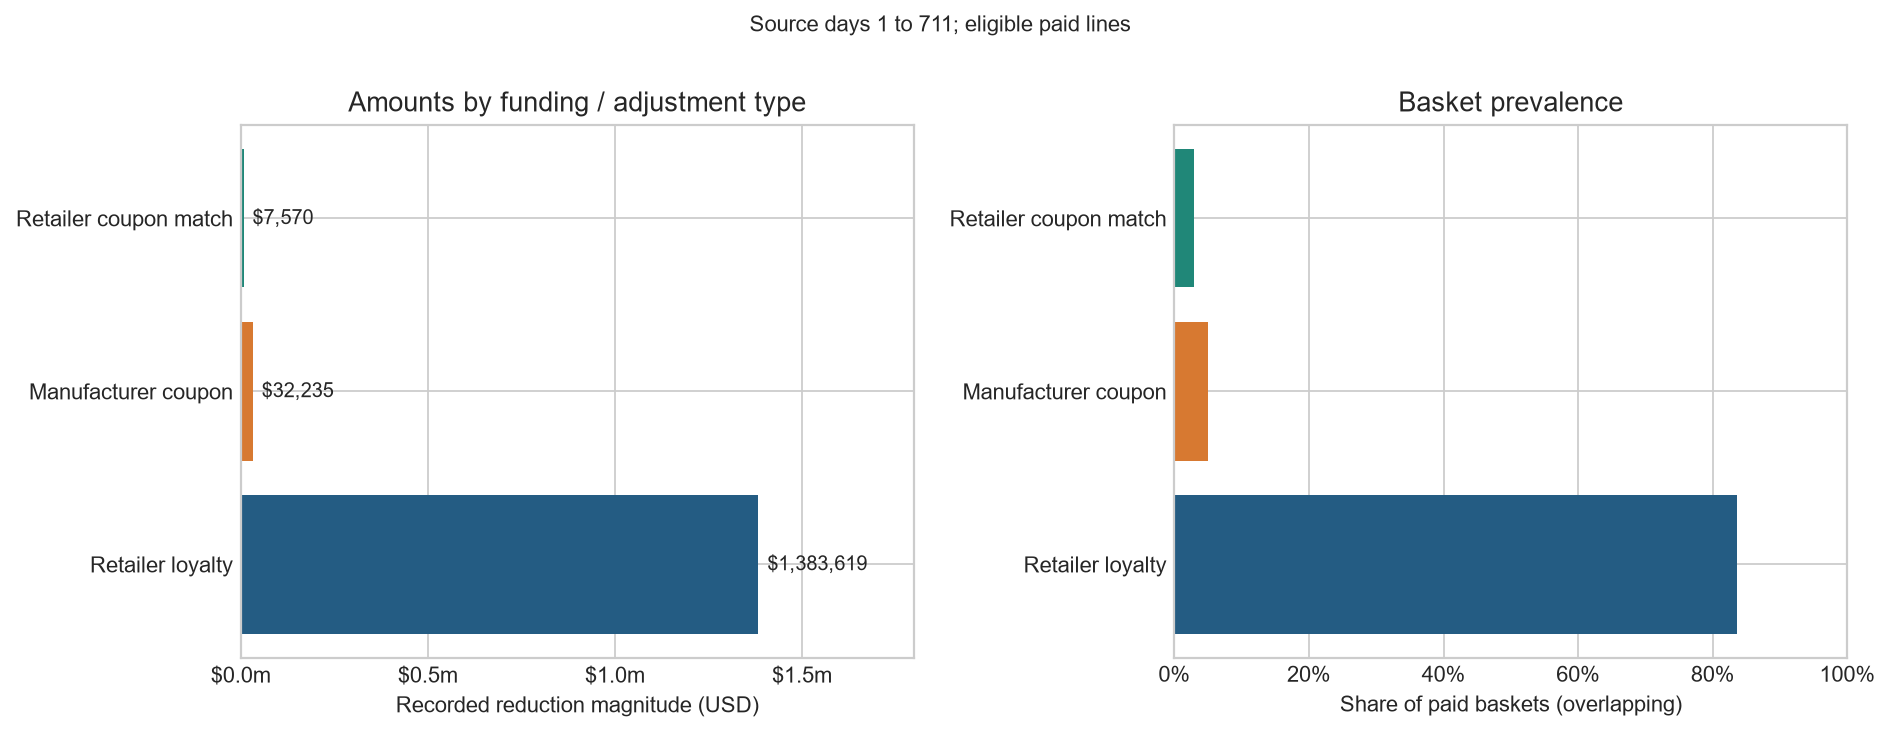

In [17]:
axes[1].set(
    xlabel="Share of paid baskets (overlapping)",
    xlim=(0, 100),
    title="Basket prevalence",
)
axes[1].xaxis.set_major_formatter(PercentFormatter(100))
fig.suptitle(window_label, fontsize=10, y=1.01)
finish_figure(fig, "03_discount_amounts_and_prevalence.png")


## 4. Reconcile and export category/discount aggregates

Category partitions must preserve exact eligible sales. Local exports are kept in Git-ignored data/processed/eda. No placement file is read or promotion-matching table created in this notebook.

**Step 18: Check the calculation.**

In [18]:
total = con.execute("""SELECT sum(sales_value)
FROM eda_lines""").fetchone()[0]
partition = con.execute("""SELECT sum(sales)
FROM
  (SELECT category,sum(sales_value) AS sales
   FROM eda_lines
   GROUP BY category)""").fetchone()[0]
assert total == partition
out = ROOT / "data/processed/eda"
out.mkdir(parents=True, exist_ok=True)


**Step 19: Continue the calculation.**

In [19]:
for name, frame in {
    "category_metrics": category_metrics,
    "weekly_discounts": weekly_discounts,
    "discount_totals": discount_totals,
    "positive_adjustments": positive_adjustments,
}.items():
    frame.to_csv(out / (name + ".csv"), index=False)
print(
    "Exact category sales reconciliation passed. Saved 3 figures "
    "and 4 local aggregate tables."
)
con.close()


Exact category sales reconciliation passed. Saved 3 figures and 4 local aggregate tables.
